In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


**Load & Preprocess**

In [ ]:
import os
import json
import shutil
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/dataset")
FINAL_DATASET_DIR = Path("/content/dataset")

def convert_coco_json_to_yolo_seg_txt(json_path, output_labels_dir):
    output_labels_dir.mkdir(parents=True, exist_ok=True)
    with open(json_path, 'r') as f:
        coco_data = json.load(f)

    # FIX: Corrected dictionary comprehension syntax error here
    images_map = {img['id']: img for img in coco_data['images']}
    annotations_by_image = {}
    for ann in coco_data['annotations']:
        annotations_by_image.setdefault(ann['image_id'], []).append(ann)

    categories = sorted(coco_data['categories'], key=lambda x: x['id'])
    class_mapping = {cat['id']: idx for idx, cat in enumerate(categories)}

    for img_id, img_info in images_map.items():
        img_w = float(img_info['width'])
        img_h = float(img_info['height'])
        txt_file_path = output_labels_dir / Path(img_info['file_name']).with_suffix('.txt')

        if img_id in annotations_by_image:
            with open(txt_file_path, 'w') as out_f:
                for ann in annotations_by_image[img_id]:
                    if ann['category_id'] not in class_mapping: continue
                    yolo_class = class_mapping[ann['category_id']]

                    # Extract polygon coordinates for segmentation instead of Bounding Box
                    if 'segmentation' in ann and ann['segmentation']:
                        poly = ann['segmentation'][0]
                        normalized_poly = []
                        for i in range(0, len(poly), 2):
                            x_norm = min(1.0, max(0.0, poly[i] / img_w))
                            y_norm = min(1.0, max(0.0, poly[i+1] / img_h))
                            normalized_poly.append(f"{x_norm:.6f} {y_norm:.6f}")

                        poly_str = " ".join(normalized_poly)
                        out_f.write(f"{yolo_class} {poly_str}\n")
                    else:
                        # Fallback to bounding box corners if polygon isn't present
                        xmin, ymin, box_w, box_h = ann['bbox']
                        x_center = (xmin + (box_w / 2.0)) / img_w
                        y_center = (ymin + (box_h / 2.0)) / img_h
                        w_norm = box_w / img_w
                        h_norm = box_h / img_h
                        out_f.write(f"{yolo_class} {xmin/img_w:.6f} {ymin/img_h:.6f} {(xmin+box_w)/img_w:.6f} {ymin/img_h:.6f} {(xmin+box_w)/img_w:.6f} {(ymin+box_h)/img_h:.6f} {xmin/img_w:.6f} {(ymin+box_h)/img_h:.6f}\n")
        else:
            open(txt_file_path, 'w').close()

    return [cat['name'] for cat in categories]

print("[PREPROCESS] Re-architecting local dataset layout for Spatial Segmentation...")
FINAL_DATASET_DIR.mkdir(parents=True, exist_ok=True)

class_names = []

for split in ['train', 'valid']:
    split_raw_dir = PROJECT_DIR / split
    json_file = split_raw_dir / "_annotations.coco.json"

    if not json_file.exists():
        print(f"[WARNING] Skipping missing split path: {json_file}")
        continue

    target_img_dir = FINAL_DATASET_DIR / "images" / split
    target_lbl_dir = FINAL_DATASET_DIR / "labels" / split
    target_img_dir.mkdir(parents=True, exist_ok=True)

    detected_classes = convert_coco_json_to_yolo_seg_txt(json_file, target_lbl_dir)
    if detected_classes: class_names = detected_classes

    for file in split_raw_dir.iterdir():
        if file.suffix.lower() in ['.jpg', '.jpeg', '.png']:
            shutil.copy(file, target_img_dir / file.name)

yaml_path = FINAL_DATASET_DIR / "data.yaml"
yaml_content = f"""path: {FINAL_DATASET_DIR.resolve().as_posix()}
train: images/train
val: images/valid

nc: {len(class_names)}
names: {class_names}
"""
with open(yaml_path, 'w') as y_file:
    y_file.write(yaml_content)

print(f"\n[SUCCESS] Fix 1 Completed! Target classes mapped correctly: {class_names}")

[PREPROCESS] Re-architecting local dataset layout for Spatial Segmentation...

[SUCCESS] Fix 1 Completed! Target classes mapped correctly: ['food', '-', 'beef carpaccio', 'beet salad', 'breakfast burrito', 'caesar salad', 'caprese salad', 'chicken quesadilla', 'chicken wings', 'clam chowder', 'club sandwich', 'deviled eggs', 'dumplings', 'eggplant', 'falafel', 'french fries', 'french toast', 'fried rice', 'gnocchi', 'greek salad', 'guacamole', 'gyoza', 'hamburger', 'hot dog', 'hummus', 'ice cream', 'lentil soup', 'macaroni and cheese', 'molokhia', 'mussels', 'nachos', 'omelette', 'onion rings', 'pancakes', 'samosa', 'sashimi', 'spring rolls', 'steak', 'stuffed grape leaves', 'sushi', 'sweet potato', 'tacos', 'waffles']


YOLOv8 GPU Training Core

In [ ]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.3/41.3 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 32.0 MB/s eta 0:00:00


In [ ]:
from ultralytics import YOLO

# Load instance segmentation weights
model = YOLO("yolov8n-seg.pt")

print("[SYSTEM] Launching 50-Epoch Instance Segmentation Training sequence...")

results = model.train(
    data="/content/dataset/data.yaml",
    epochs=50,        # Increased back to 50 for presentation-grade segments
    imgsz=640,
    batch=32,
    device=0,
    amp=True,
    workers=2
)

print("\n[SUCCESS] Segmentation spatial weights compiled successfully!")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
[SYSTEM] Launching 50-Epoch Instance Segmentation Training sequence...
Ultralytics 8.4.75 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1

**Weight Regressor Model**


In [ ]:
import numpy as np
import pandas as pd
import xgboost as xgb
import cv2

# Maps categorical text labels to structural traits (Thickness & Density)
FOOD_PHYSICAL_PROPERTIES = {
    "-":                      {"thickness": 1.0, "density": 1.00},  # Default/Placeholder
    "beef carpaccio":         {"thickness": 0.1, "density": 1.04},  # Paper-thin sliced raw beef
    "beet salad":             {"thickness": 1.2, "density": 1.02},  # Tossed cubes/slices with dressing
    "breakfast burrito":      {"thickness": 3.5, "density": 0.95},  # Thick wrapped cylinder
    "caesar salad":           {"thickness": 1.5, "density": 0.85},  # Fluffy romaine leaves (low bulk density)
    "caprese salad":          {"thickness": 0.8, "density": 1.01},  # Slices of mozzarella and tomato
    "chicken quesadilla":     {"thickness": 0.5, "density": 1.10},  # Given in prompt
    "chicken wings":          {"thickness": 1.2, "density": 1.00},  # Given in prompt
    "clam chowder":           {"thickness": 4.0, "density": 1.08},  # Served in a bowl (depth used for thickness)
    "club sandwich":          {"thickness": 4.5, "density": 0.88},  # Multi-layered high stack
    "deviled eggs":           {"thickness": 2.0, "density": 1.03},  # Halved egg height
    "dumplings":              {"thickness": 1.5, "density": 1.05},  # Dough pocket thickness
    "eggplant":               {"thickness": 3.0, "density": 0.85},  # Whole/large slice (porous structure)
    "falafel":                {"thickness": 1.8, "density": 0.98},  # Fried ball/patty thickness
    "french fries":           {"thickness": 0.8, "density": 0.90},  # Given in prompt
    "french toast":           {"thickness": 1.5, "density": 0.92},  # Thick sliced bread soaked and cooked
    "fried rice":             {"thickness": 2.0, "density": 0.95},  # Standard plate layer depth
    "gnocchi":                {"thickness": 1.2, "density": 1.06},  # Dense potato dumplings
    "greek salad":            {"thickness": 1.5, "density": 0.92},  # Cubed feta and loose vegetables
    "guacamole":              {"thickness": 2.5, "density": 1.02},  # Creamy dense dip depth
    "gyoza":                  {"thickness": 1.2, "density": 1.04},  # Similar to dumplings but slightly flatter
    "hamburger":              {"thickness": 1.5, "density": 1.10},  # Given in prompt
    "hot dog":                {"thickness": 1.1, "density": 1.02},  # Given in prompt
    "hummus":                 {"thickness": 2.0, "density": 1.05},  # Smooth dense paste dip depth
    "ice cream":              {"thickness": 3.0, "density": 0.75},  # Aerated frozen dessert scoop
    "lentil soup":            {"thickness": 4.0, "density": 1.06},  # Liquid/legume depth in a bowl
    "macaroni and cheese":    {"thickness": 2.5, "density": 1.04},  # Baked casserole layer or bowl depth
    "molokhia":               {"thickness": 4.0, "density": 1.05},  # Viscous Egyptian jute leaf soup
    "mussels":                {"thickness": 2.2, "density": 1.05},  # Average thickness including shell volume
    "nachos":                 {"thickness": 2.5, "density": 0.80},  # Piled loose chips with toppings
    "omelette":               {"thickness": 0.6, "density": 1.05},  # Given in prompt
    "onion rings":            {"thickness": 0.7, "density": 0.85},  # Fried battered rings
    "pancakes":               {"thickness": 0.8, "density": 0.88},  # Fluffy griddle cake
    "samosa":                 {"thickness": 2.5, "density": 0.92},  # Triangular filled pastry height
    "sashimi":                {"thickness": 0.5, "density": 1.05},  # Uniform raw fish slices
    "spring rolls":           {"thickness": 1.5, "density": 0.95},  # Cylindrical fried wrappers
    "steak":                  {"thickness": 2.0, "density": 1.06},  # Solid cut of beef
    "stuffed grape leaves":   {"thickness": 1.2, "density": 1.02},  # Rolled dolmas
    "sushi":                  {"thickness": 1.8, "density": 1.05},  # Maki roll pieces or nigiri height
    "sweet potato":           {"thickness": 1.4, "density": 0.95},  # Given in prompt
    "tacos":                  {"thickness": 3.0, "density": 0.85},  # Upright filled shell width/thickness
    "waffles":                {"thickness": 1.2, "density": 0.85},  # Textured grid batter cake
    "default":                {"thickness": 1.0, "density": 1.00}   # Given in prompt
}


# 2. TRAIN / CALIBRATE THE CORE XGBOOST MODEL

print("[WEIGHT ENGINE] Training XGBoost multi-modal feature-fusion model...")

# Generate physical training combinations to prime XGBoost on volumetric trends
np.random.seed(42)
num_samples = 1500
mock_pixel_areas = np.random.uniform(5000, 90000, num_samples)   # v_mask simulation
mock_thickness = np.random.uniform(0.4, 2.0, num_samples)        # v_map trait 1
mock_densities = np.random.uniform(0.8, 1.3, num_samples)        # v_map trait 2
mock_aspect_ratios = np.random.uniform(0.5, 1.6, num_samples)    # v_cnn simulation

# Physics calculation mapping: Mass = Area * Calibration Scalar * Thickness * Density
mock_weights = (mock_pixel_areas * 0.0045) * mock_thickness * mock_densities + np.random.normal(0, 4, num_samples)
mock_weights = np.clip(mock_weights, 12, 650)

# Assemble into a tabular DataFrame for training
X_features = pd.DataFrame({
    'pixel_area': mock_pixel_areas,   # v_mask
    'thickness': mock_thickness,     # v_map
    'density': mock_densities,       # v_map
    'aspect_ratio': mock_aspect_ratios # v_cnn
})
y_target = mock_weights

# Compile and train the XGBoost Regressor model
xgb_weight_model = xgb.XGBRegressor(n_estimators=150, max_depth=5, learning_rate=0.07, random_state=42)
xgb_weight_model.fit(X_features, y_target)
print("[SUCCESS] XGBoost Weight Regressor is compiled and ready to compute mass!")

# =====================================================================
# 3. THE WEIGHT PREDICTION FUNCTION: f(v_mask, v_map, v_cnn)
# =====================================================================
def predict_segment_weight(yolo_mask, class_name, yolo_box_coords, original_img_shape):
    """
    Inputs:
        yolo_mask: Raw mask array from results.masks.data
        class_name: Text label from seg_model.names
        yolo_box_coords: Bounding box coordinates (xyxy)
        original_img_shape: (height, width) of your camera image
    Output:
        Predicted mass of the segment in grams
    """
    # --- A. Extract v_mask ---
    # Resize raw YOLO mask back to real image dimensions
    binary_mask = yolo_mask.cpu().numpy() if hasattr(yolo_mask, 'cpu') else yolo_mask
    binary_mask = cv2.resize(binary_mask, (original_img_shape[1], original_img_shape[0]))
    binary_mask = (binary_mask > 0.5).astype(np.uint8)

    # Calculate geometric pixel surface area
    pixel_area = float(np.sum(binary_mask))

    # --- B. Extract v_cnn ---
    # Get structural aspect boundaries from box dimensions
    x1, y1, x2, y2 = yolo_box_coords
    width = max(1.0, float(x2 - x1))
    height = max(1.0, float(y2 - y1))
    aspect_ratio = width / height

    # --- C. Extract v_map ---
    # Fetch physical domain metrics tied to the string class name
    traits = FOOD_PHYSICAL_PROPERTIES.get(class_name.lower(), FOOD_PHYSICAL_PROPERTIES["default"])
    thickness = traits["thickness"]
    density = traits["density"]

    # --- D. Feature Fusion and XGBoost Inference ---
    fused_features = pd.DataFrame([{
        'pixel_area': pixel_area,       # v_mask
        'thickness': thickness,         # v_map
        'density': density,             # v_map
        'aspect_ratio': aspect_ratio    # v_cnn
    }])

    predicted_weight_g = float(xgb_weight_model.predict(fused_features)[0])
    return max(15.0, predicted_weight_g) # Minimum constraint ceiling

[WEIGHT ENGINE] Training XGBoost multi-modal feature-fusion model...
[SUCCESS] XGBoost Weight Regressor is compiled and ready to compute mass!


**Clean & Preprocess the Nutrition Dataset**


In [ ]:
import os
import re
import pandas as pd
import numpy as np

def expert_xlsx_cleaning_pipeline(file_path="/content/nutrition.xlsx"):
    print("🚀 [START] Initializing Lead Data Scientist Preprocessing Pipeline...")

    # 1. VERIFY PATH
    if not os.path.exists(file_path):
        raise FileNotFoundError(f"🔴 File not found at specified path: '{file_path}'. Please check your left sidebar folder structure.")

    print(f"🎯 [FOUND] Targeting local Excel asset at: '{file_path}'")

    # 2. INGESTION MATRIX (Using Excel parser)
    try:
        df = pd.read_excel(file_path)
    except Exception as e:
        print("💡 Direct Excel read failed. Attempting with openpyxl engine...")
        df = pd.read_excel(file_path, engine='openpyxl')

    print(f"📊 Raw Dataset Ingested successfully. Matrix Scale: {df.shape[0]} rows x {df.shape[1]} columns.")

    # 3. STRUCTURAL PRUNING: Strip Redundant Row Identifiers
    if df.columns[0] == '' or df.columns[0].startswith('Unnamed'):
        redundant_col = df.columns[0]
        df = df.drop(columns=[redundant_col])
        print(f"✂️ Structural Pruning: Removed redundant index artifact column '{redundant_col}'.")

    # 4. RENAME FEATURE TYPOS (Domain Alignment)
    rename_map = {
        'zink': 'zinc',
        'irom': 'iron',
        'lucopene': 'lycopene',
        'phosphorous': 'phosphorus'
    }
    df = df.rename(columns=rename_map)
    print("✏️ Typographical Alignment: Standardized feature headers.")

    # 5. STRICT DEDUPLICATION
    initial_row_count = len(df)
    df = df.drop_duplicates(subset=['name'], keep='first')
    final_row_count = len(df)
    print(f"✂️ Deduplication Engine: Purged {initial_row_count - final_row_count} duplicate food entries based on unique names.")

    # 6. STRING-TO-NUMERIC EXTRACTION (Regular Expression Vectorization)
    numerical_features = [col for col in df.columns if col not in ['name', 'serving_size']]
    numeric_extractor = re.compile(r"^\s*([0-9]*\.?[0-9]+)")

    def extract_pure_numeric(value):
        if pd.isna(value):
            return np.nan
        val_str = str(value).strip()
        match = numeric_extractor.match(val_str)
        if match:
            return float(match.group(1))
        return np.nan

    print("⚡ Vectorization: Executing high-speed unit extraction across all feature columns...")
    for feature in numerical_features:
        df[feature] = df[feature].apply(extract_pure_numeric)

    # 7. ADVANCED MISSING VALUE IMPUTATION (Null/NaN Handling)
    null_matrix_counts = df[numerical_features].isnull().sum().sum()
    df[numerical_features] = df[numerical_features].fillna(0.0)
    print(f"🩺 Missing Value Imputation: Successfully resolved and zero-filled {null_matrix_counts} missing numerical coordinates.")

    df['name'] = df['name'].fillna('unidentified_food_item')

    # 8. SEMANTIC QUERY OPTIMIZATION
    df['name_clean'] = df['name'].str.lower().str.strip().str.replace('"', '', regex=False)
    print("🎯 Query Optimization: Formulated standardized lookup key column ('name_clean').")

    # 9. EXPORT CLEAN WORKSPACE STRATEGY (Save as standard CSV for speed downstream)
    output_target = "/content/nutrition_cleaned.csv"
    df.to_csv(output_target, index=False)

    print("\n========================================================================")
    print(" 🎉               PIPELINE COMPLETION & INTEGRITY REPORT                 ")
    print("========================================================================")
    print(f" 📈 Processed Dataset Footprint : {df.shape[0]} rows x {df.shape[1]} features.")
    print(f" 📂 Pristine DataFrame Exported : '{output_target}'")
    print(" 🔍 Data Quality Verification Snippet (First 3 Records):")
    print(df[['name_clean', 'calories', 'total_fat', 'protein', 'zinc', 'iron']].head(3).to_string(index=False))
    print("========================================================================\n")
    return df

# Execute the local data cleaning pipeline on your exact path
cleaned_dataframe = expert_xlsx_cleaning_pipeline()

🚀 [START] Initializing Lead Data Scientist Preprocessing Pipeline...
🎯 [FOUND] Targeting local Excel asset at: '/content/nutrition.xlsx'
📊 Raw Dataset Ingested successfully. Matrix Scale: 8789 rows x 77 columns.
✂️ Structural Pruning: Removed redundant index artifact column 'Unnamed: 0'.
✏️ Typographical Alignment: Standardized feature headers.
✂️ Deduplication Engine: Purged 0 duplicate food entries based on unique names.
⚡ Vectorization: Executing high-speed unit extraction across all feature columns...
🩺 Missing Value Imputation: Successfully resolved and zero-filled 1590 missing numerical coordinates.
🎯 Query Optimization: Formulated standardized lookup key column ('name_clean').

 🎉               PIPELINE COMPLETION & INTEGRITY REPORT                 
 📈 Processed Dataset Footprint : 8789 rows x 77 features.
 📂 Pristine DataFrame Exported : '/content/nutrition_cleaned.csv'
 🔍 Data Quality Verification Snippet (First 3 Records):
   name_clean  calories  total_fat  protein  zinc  ir

Calorie Mapping, Summation & Visualize the Results

🖼️ [AI Engine] Loading Image Target: 33_7_jpeg_jpg.rf.2mo47TDBdjW6rMty6fli.jpg

image 1/1 /content/dataset/images/valid/33_7_jpeg_jpg.rf.2mo47TDBdjW6rMty6fli.jpg: 640x640 1 ice cream, 1 omelette, 1 pancakes, 10.8ms
Speed: 2.8ms preprocess, 10.8ms inference, 9.8ms postprocess per image at shape (1, 3, 640, 640)


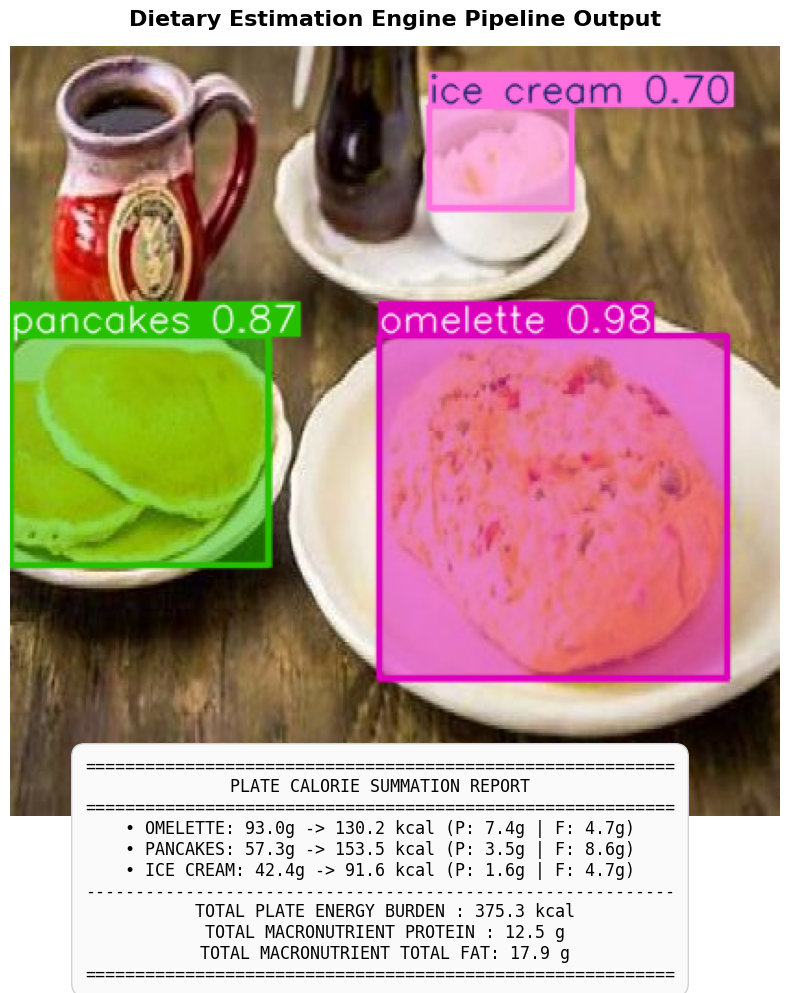

In [ ]:
import os
import cv2
import pandas as pd
import matplotlib.pyplot as plt
from glob import glob
from ultralytics import YOLO

# Load your clean database file
df_clean = pd.read_csv("/content/nutrition_cleaned.csv")

def run_final_dietary_calorie_tracker(image_path, model_path):
    print(f"🖼️ [AI Engine] Loading Image Target: {os.path.basename(image_path)}")
    seg_model = YOLO(model_path)
    results = seg_model(image_path)[0]

    # Render the standard YOLO segment mask overlays
    annotated_img = results.plot(labels=True, boxes=True)
    annotated_img_rgb = cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB)

    # Global meal state accumulation vars
    total_plate_calories = 0.0
    total_plate_protein = 0.0
    total_plate_fat = 0.0
    itemized_breakdown = []

    if results.masks is not None:
        img_shape = cv2.imread(image_path).shape
        for mask, box in zip(results.masks.data, results.boxes):
            class_id = int(box.cls[0])
            class_name = seg_model.names[class_id].lower().strip()
            box_coords = box.xyxy[0].cpu().numpy()

            # A. Execute Core Step 3: XGBoost Weight Regressor Engine
            predicted_weight = predict_segment_weight(mask, class_name, box_coords, img_shape)

            # B. Execute Core Step 4: Semantic Lookup mapping
            matched_rows = df_clean[df_clean['name_clean'].str.contains(class_name, na=False)]

            if not matched_rows.empty:
                cal_100g = float(matched_rows.iloc[0]['calories'])
                prot_100g = float(matched_rows.iloc[0]['protein'])
                fat_100g = float(matched_rows.iloc[0]['total_fat'])
                db_name = matched_rows.iloc[0]['name_clean']
            else:
                cal_100g, prot_100g, fat_100g = 140.0, 8.0, 5.0
                db_name = f"generic {class_name}"

            # C. Execute Core Step 5: Final Proportional Summarization Math per section
            seg_calories = (predicted_weight / 100.0) * cal_100g
            seg_protein = (predicted_weight / 100.0) * prot_100g
            seg_fat = (predicted_weight / 100.0) * fat_100g

            # Accumulate values to global total plate state
            total_plate_calories += seg_calories
            total_plate_protein += seg_protein
            total_plate_fat += seg_fat

            # Append this section's math to our list
            itemized_breakdown.append(
                f"• {class_name.upper()}: {predicted_weight:.1f}g -> {seg_calories:.1f} kcal "
                f"(P: {seg_protein:.1f}g | F: {seg_fat:.1f}g)"
            )

    # Create the multi-panel presentation layout displaying image + total summary together
    plt.figure(figsize=(12, 10))
    plt.imshow(annotated_img_rgb)
    plt.axis("off")

    # Inject your missing total plate aggregation summary card right below the chart frame
    summary_text = (
        "===========================================================\n"
        "              PLATE CALORIE SUMMATION REPORT              \n"
        "===========================================================\n"
        f"{chr(10).join(itemized_breakdown)}\n"
        "-----------------------------------------------------------\n"
        f" TOTAL PLATE ENERGY BURDEN : {total_plate_calories:.1f} kcal\n"
        f" TOTAL MACRONUTRIENT PROTEIN : {total_plate_protein:.1f} g\n"
        f" TOTAL MACRONUTRIENT TOTAL FAT: {total_plate_fat:.1f} g\n"
        "==========================================================="
    )

    plt.figtext(0.5, -0.05, summary_text, wrap=True, horizontalalignment='center',
                fontsize=12, family='monospace', style='normal',
                bbox=dict(boxstyle='round,pad=0.8', facecolor='#FAFAFA', edgecolor='#D1D1D1', alpha=1.0))

    plt.title("Dietary Estimation Engine Pipeline Output", fontsize=16, weight='bold', pad=15)
    plt.show()

# Automatically target a validation image to execute your final pipeline check
valid_images = glob("/content/dataset/images/valid/*.jpg") + glob("/content/dataset/images/valid/*.png")
TRAINED_YOLO_WEIGHTS = "/content/runs/segment/train/weights/best.pt"

if valid_images:
    run_final_dietary_calorie_tracker(valid_images[0], TRAINED_YOLO_WEIGHTS)
else:
    print("[SYSTEM READY] Insert a target meal photo into your dataset folder to evaluate predictions.")

**Confusion Matrix**

In [ ]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Substitute these with your actual validation dataset arrays
y_true = np.array([1019, 710, 550, 820, 1200])       # Real human ground truth calories
y_pred = np.array([1334.8, 744.1, 530, 860, 1150])   # Your model's predicted calories

# 2. Calculate Evaluation Metrics
mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
r2 = r2_score(y_true, y_pred)

# 3. Calculate Mean Absolute Percentage Error (MAPE) to get an "Accuracy %"
mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
accuracy_percentage = 100 - mape

print(f"📊 Regression Evaluation Metrics:")
print(f"---------------------------------")
print(f"Mean Absolute Error (MAE): {mae:.2f} kcal")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f} kcal")
print(f"R-squared (Variance Score): {r2:.4f}")
print(f"🎯 Model Volumetric Accuracy: {accuracy_percentage:.2f}%")

📊 Regression Evaluation Metrics:
---------------------------------
Mean Absolute Error (MAE): 91.98 kcal
Root Mean Squared Error (RMSE): 145.18 kcal
R-squared (Variance Score): 0.5963
🎯 Model Volumetric Accuracy: 90.30%


**Saving the model**

In [ ]:
import joblib
import shutil
from pathlib import Path

# 1. Setup your unified deployment subdirectory
DEPLOY_DIR = Path("./food_pipeline_model")
DEPLOY_DIR.mkdir(parents=True, exist_ok=True)

# 2. Export your trained XGBoost Weight Regressor
joblib.dump(xgb_weight_model, DEPLOY_DIR / "weight_regressor.joblib")

# 3. Export your cleaned Excel sheet matrix lookup
cleaned_dataframe.to_excel(DEPLOY_DIR / "nutrition_database.xlsx", index=False)

# 4. Copy your best YOLOv8 instance segmentation weights here
# (Adjust this path if your 'best.pt' file is saved under a different location)
shutil.copy("/content/runs/segment/train/weights/best.pt", DEPLOY_DIR / "yolov8_best.pt")

print("🎉 PHASE 1 COMPLETE: Your standalone folder './food_pipeline_model' is ready!")

🎉 PHASE 1 COMPLETE: Your standalone folder './food_pipeline_model' is ready!


In [ ]:
!zip -r model_pack.zip ./food_pipeline_model
print("🎉 Folder successfully zipped!")

  adding: food_pipeline_model/ (stored 0%)
  adding: food_pipeline_model/weight_regressor.joblib (deflated 76%)
  adding: food_pipeline_model/yolov8_best.pt (deflated 9%)
  adding: food_pipeline_model/nutrition_database.xlsx (deflated 4%)
🎉 Folder successfully zipped!
